In [5]:

# ================================================================
# EXERCISE 1: MULTIPLE LINEAR REGRESSION
# Insurance Cost Prediction
# Python 3.12 | Pandas | NumPy | Scikit-Learn | Matplotlib
# ================================================================

# Install required libraries:
# python -m pip install pandas numpy scikit-learn matplotlib

import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

matplotlib.use("Agg")
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

# ================================================================
# 1. CONFIGURATION
# ================================================================

RANDOM_STATE = 42

OUTPUT_DIR = Path("exercise1_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(exist_ok=True)

CSV_DIR = OUTPUT_DIR / "csv"
CSV_DIR.mkdir(exist_ok=True)

print("=" * 70)
print("EXERCISE 1: INSURANCE COST PREDICTION")
print("=" * 70)


# ================================================================
# 2. LOAD DATASET
# ================================================================

dataset_path = Path("insurance.csv")

if not dataset_path.exists():
    print("insurance.csv not found. Downloading dataset...")

    url = (
        "https://raw.githubusercontent.com/"
        "stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
    )

    try:
        request = urllib.request.Request(
            url,
            headers={"User-Agent": "Mozilla/5.0"},
        )

        with urllib.request.urlopen(request, timeout=60) as response:
            dataset_path.write_bytes(response.read())

        print("Dataset downloaded successfully.")

    except Exception as error:
        raise FileNotFoundError(
            "Could not download insurance.csv. "
            "Download the Medical Cost Personal Data dataset "
            "and place insurance.csv in the same folder as this script."
        ) from error

df = pd.read_csv(dataset_path)

df.columns = df.columns.str.strip().str.lower()

required_columns = [
    "age", "sex", "bmi", "children",
    "smoker", "region", "charges",
]

missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five records:")
print(df.head().to_string(index=False))

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDescriptive statistics:")
print(df.describe(include="all").to_string())


# ================================================================
# 3. DATA QUALITY CHECKS
# ================================================================

print("\n" + "=" * 70)
print("DATA QUALITY CHECKS")
print("=" * 70)

print("Duplicate rows:", df.duplicated().sum())

print("\nCharges summary:")
print(df["charges"].describe())

print("\nCharges skewness:", round(df["charges"].skew(), 4))

if df["charges"].skew() > 1.5:
    print("Charges have strong positive skewness.")
else:
    print("Charges skewness is lower than the guide's > 1.5 benchmark.")

# Do not silently remove potentially legitimate observations.
# Drop duplicate rows only if your assignment requires it.
# The default analysis preserves all rows from the supplied dataset.


# ================================================================
# 4. TARGET DISTRIBUTION
# ================================================================

plt.figure(figsize=(9, 5))

plt.hist(
    df["charges"].dropna(),
    bins=35,
    edgecolor="black",
)

plt.title("Distribution of Insurance Charges")
plt.xlabel("Medical Charges ($)")
plt.ylabel("Frequency")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "01_charges_distribution.png",
    dpi=150,
)

plt.close()

print("\nSaved: 01_charges_distribution.png")


# ================================================================
# 5. DEFINE FEATURES AND TARGET
# ================================================================

numeric_columns = ["age", "bmi", "children"]

categorical_columns = ["sex", "smoker", "region"]

feature_columns = numeric_columns + categorical_columns

X = df[feature_columns].copy()
y = df["charges"].copy()

print("\nFeatures:", feature_columns)
print("Target: charges")


# ================================================================
# 6. TRAIN-TEST SPLIT
# ================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("Training proportion:", round(len(X_train) / len(X), 2))
print("Testing proportion:", round(len(X_test) / len(X), 2))


# ================================================================
# 7. BUILD PREPROCESSING PIPELINE
# ================================================================

try:
    encoder = OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False,
    )
except TypeError:
    # Compatibility with older Scikit-Learn versions.
    encoder = OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse=False,
    )

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_columns),
        ("cat", categorical_pipeline, categorical_columns),
    ],
    remainder="drop",
)

print("\nPreprocessing pipeline created:")
print("- Numeric features: median imputation + StandardScaler")
print("- Categorical features: most-frequent imputation + OneHotEncoder")
print("- OneHotEncoder uses drop='first'")


# ================================================================
# 8. TRAIN MULTIPLE LINEAR REGRESSION
# ================================================================

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression()),
])

model.fit(X_train, y_train)

print("\nLinear Regression model trained successfully!")


# ================================================================
# 9. PREDICT TEST DATA
# ================================================================

y_pred = model.predict(X_test)

print("\nFirst 10 predictions:")

preview = pd.DataFrame({
    "Actual_Charges": y_test.to_numpy()[:10],
    "Predicted_Charges": y_pred[:10],
})

print(preview.round(2).to_string(index=False))


# ================================================================
# 10. EVALUATE MODEL
# ================================================================

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n" + "=" * 70)
print("RAW-TARGET REGRESSION RESULTS")
print("=" * 70)

print(f"Mean Squared Error (MSE):  ${mse:,.2f}")
print(f"Root Mean Squared Error:   ${rmse:,.2f}")
print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"R-squared (R²):             {r2:.4f}")

print("\nLab acceptance targets:")
print("R² >= 0.75:", "PASS" if r2 >= 0.75 else "NOT MET")
print("RMSE < $4,800:", "PASS" if rmse < 4800 else "NOT MET")


# ================================================================
# 11. BENCHMARK LOG-TRANSFORMED TARGET
# ================================================================

log_model = Pipeline([
    ("preprocessor", ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]),
                numeric_columns,
            ),
            (
                "cat",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", encoder),
                ]),
                categorical_columns,
            ),
        ],
        remainder="drop",
    )),
    ("regressor", LinearRegression()),
])

# Train only on log-transformed training targets.
log_model.fit(X_train, np.log1p(y_train))

# Transform predictions back into dollar units.
log_pred = np.expm1(log_model.predict(X_test))

# Guard against impossible negative expense predictions.
log_pred = np.maximum(log_pred, 0)

log_rmse = np.sqrt(mean_squared_error(y_test, log_pred))
log_mae = mean_absolute_error(y_test, log_pred)
log_r2 = r2_score(y_test, log_pred)

print("\n" + "=" * 70)
print("LOG-TRANSFORMED TARGET RESULTS")
print("=" * 70)

print(f"RMSE: ${log_rmse:,.2f}")
print(f"MAE:  ${log_mae:,.2f}")
print(f"R²:    {log_r2:.4f}")

print("\nComparison:")
print(f"{'Metric':<15}{'Raw Target':>18}{'Log Target':>18}")
print("-" * 51)
print(f"{'RMSE ($)':<15}{rmse:>18,.2f}{log_rmse:>18,.2f}")
print(f"{'MAE ($)':<15}{mae:>18,.2f}{log_mae:>18,.2f}")
print(f"{'R²':<15}{r2:>18.4f}{log_r2:>18.4f}")

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression - Raw Charges",
        "Linear Regression - Log1p Charges",
    ],
    "RMSE": [rmse, log_rmse],
    "MAE": [mae, log_mae],
    "R2": [r2, log_r2],
})

comparison.to_csv(
    CSV_DIR / "model_comparison.csv",
    index=False,
)


# ================================================================
# 12. INSPECT REGRESSION COEFFICIENTS
# ================================================================

fitted_preprocessor = model.named_steps["preprocessor"]

feature_names = fitted_preprocessor.get_feature_names_out()

coefficients = model.named_steps["regressor"].coef_

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
})

coefficient_df = coefficient_df.sort_values(
    "Coefficient",
    ascending=False,
)

intercept = model.named_steps["regressor"].intercept_

print("\n" + "=" * 70)
print("REGRESSION COEFFICIENTS")
print("=" * 70)

print(f"Intercept: ${intercept:,.2f}")

print("\nCoefficients:")
print(coefficient_df.round(4).to_string(index=False))

coefficient_df.to_csv(
    CSV_DIR / "regression_coefficients.csv",
    index=False,
)

# The guide expects the smoker effect to exceed $23,000.
# Since the numeric predictors are standardized, the encoded smoker
# coefficient represents the adjusted difference in the model's
# predicted charges when the other encoded features are held constant.

smoker_rows = coefficient_df[
    coefficient_df["Feature"].str.contains(
        "smoker_yes",
        case=False,
        regex=False,
    )
]

if not smoker_rows.empty:
    smoker_effect = float(smoker_rows.iloc[0]["Coefficient"])

    print(f"\nEstimated smoker coefficient: ${smoker_effect:,.2f}")

    print(
        "Smoker effect > $23,000:",
        "PASS" if smoker_effect > 23000 else "NOT MET",
    )
else:
    print(
        "\nCould not find smoker_yes among the encoded features. "
        "Inspect the feature names and category values."
    )


# ================================================================
# 13. ACTUAL VS PREDICTED PLOT
# ================================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred,
    y_test,
    alpha=0.65,
    edgecolors="none",
)

lower = min(float(y_test.min()), float(y_pred.min()))
upper = max(float(y_test.max()), float(y_pred.max()))

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Ideal prediction",
)

plt.xlabel("Predicted Charges ($)")
plt.ylabel("Actual Charges ($)")
plt.title("Actual vs Predicted Insurance Charges")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "02_actual_vs_predicted.png",
    dpi=150,
)

plt.close()

print("\nSaved: 02_actual_vs_predicted.png")


# ================================================================
# 14. RESIDUAL DIAGNOSTICS
# ================================================================

residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.65,
    edgecolors="none",
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
)

plt.xlabel("Fitted Values ($)")
plt.ylabel("Residuals ($)")
plt.title("Residuals vs Fitted Values")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "03_residuals_vs_fitted.png",
    dpi=150,
)

plt.close()

print("Saved: 03_residuals_vs_fitted.png")


# Residual distribution.
plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=35,
    edgecolor="black",
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
)

plt.xlabel("Residual ($)")
plt.ylabel("Frequency")
plt.title("Distribution of Regression Residuals")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "04_residual_distribution.png",
    dpi=150,
)

plt.close()

print("Saved: 04_residual_distribution.png")


# ================================================================
# 15. EXPORT TEST PREDICTIONS
# ================================================================

prediction_df = pd.DataFrame({
    "Actual_Charges": y_test.to_numpy(),
    "Predicted_Charges": y_pred,
    "Residual": residuals,
    "Absolute_Error": np.abs(residuals),
})

prediction_df.to_csv(
    CSV_DIR / "test_predictions.csv",
    index=False,
)

print("\nTest predictions exported.")


# ================================================================
# 16. EXPORT MODEL METRICS
# ================================================================

metrics_df = pd.DataFrame([
    {
        "Model": "Linear Regression - Raw Charges",
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
    },
    {
        "Model": "Linear Regression - Log1p Charges",
        "MSE": mean_squared_error(y_test, log_pred),
        "RMSE": log_rmse,
        "MAE": log_mae,
        "R2": log_r2,
    },
])

metrics_df.to_csv(
    CSV_DIR / "evaluation_metrics.csv",
    index=False,
)


# ================================================================
# 17. FINAL DIAGNOSTIC SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("EXERCISE 1 - FINAL SUMMARY")
print("=" * 70)

print(f"Total records: {len(df)}")
print(f"Training records: {len(X_train)}")
print(f"Testing records: {len(X_test)}")

print(f"\nRaw-target R²: {r2:.4f}")
print(f"Raw-target RMSE: ${rmse:,.2f}")

print(f"\nLog-target R²: {log_r2:.4f}")
print(f"Log-target RMSE: ${log_rmse:,.2f}")

print("\nAcceptance criteria:")
print(f"R² >= 0.75: {'PASS' if r2 >= 0.75 else 'NOT MET'}")
print(f"RMSE < $4,800: {'PASS' if rmse < 4800 else 'NOT MET'}")

print("\nDiagnostic interpretation:")

if log_rmse < rmse:
    print(
        "- Log transformation reduced test RMSE after predictions "
        "were converted back to dollars."
    )
else:
    print(
        "- Log transformation did not reduce test RMSE on this split."
    )

if r2 >= 0.75 and rmse < 4800:
    print("- Both primary regression acceptance targets were achieved.")
else:
    print(
        "- One or more primary acceptance targets were not achieved. "
        "Report the actual metrics; do not claim a pass."
    )

print(
    "- Inspect the residual plot for changing spread or systematic patterns."
)
print(
    "- A fan-shaped residual pattern suggests non-constant error variance."
)
print(
    "- The smoker coefficient is adjusted for the other included features."
)

print("\nOutput directory:", OUTPUT_DIR.resolve())
print("CSV files:", CSV_DIR.resolve())
print("Diagnostic plots:", PLOT_DIR.resolve())

print("\nEXERCISE 1 COMPLETED")
print("=" * 70)


EXERCISE 1: INSURANCE COST PREDICTION

Dataset loaded successfully!
Dataset shape: (1338, 7)

First five records:
 age    sex    bmi  children smoker    region     charges
  19 female 27.900         0    yes southwest 16884.92400
  18   male 33.770         1     no southeast  1725.55230
  28   male 33.000         3     no southeast  4449.46200
  33   male 22.705         0     no northwest 21984.47061
  32   male 28.880         0     no northwest  3866.85520

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+

In [7]:
# EXERCISE 2: LOGISTIC REGRESSION - BANK MARKETING
# Run this entire cell in Jupyter Notebook or Google Colab.

import io
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

RANDOM_STATE = 42
THRESHOLD = 0.35

OUT = Path("exercise2_outputs")
PLOTS = OUT / "plots"
CSVS = OUT / "csv"

PLOTS.mkdir(parents=True, exist_ok=True)
CSVS.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("EXERCISE 2: LOGISTIC REGRESSION")
print("=" * 65)


# ------------------------------------------------
# 2. ROBUST DATASET LOADER
# ------------------------------------------------

def read_bank_csv(content):
    """Read bank CSV bytes and identify the correct delimiter."""
    for separator in [";", ","]:
        try:
            data = pd.read_csv(
                io.BytesIO(content),
                sep=separator
            )
            data.columns = data.columns.str.strip().str.lower()

            if "y" in data.columns and len(data.columns) > 5:
                return data
        except Exception:
            pass

    return None


def find_bank_csv_in_zip(zip_bytes):
    """Extract bank-full.csv or bank.csv, including nested ZIP files."""
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as archive:
        members = archive.namelist()

        # Prefer the complete 45,211-row dataset.
        candidates = [
            name for name in members
            if name.lower().endswith("bank-full.csv")
        ]

        if not candidates:
            candidates = [
                name for name in members
                if name.lower().endswith("/bank.csv")
                or name.lower() == "bank.csv"
            ]

        # Handle ZIP archives containing another ZIP.
        for name in candidates:
            content = archive.read(name)

            if content[:2] == b"PK":
                try:
                    nested_data = find_bank_csv_in_zip(content)
                    if nested_data is not None:
                        return nested_data
                except Exception:
                    continue

            data = read_bank_csv(content)
            if data is not None:
                return data

        # Some mirrors use different directory or filenames.
        for name in members:
            if name.lower().endswith(".csv"):
                data = read_bank_csv(archive.read(name))
                if data is not None:
                    return data

    return None


def download_bytes(url):
    request = urllib.request.Request(
        url,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    with urllib.request.urlopen(request, timeout=90) as response:
        return response.read()


def load_bank_dataset():
    # First check files already uploaded or present in the notebook folder.
    for filename in [
        "bank-full.csv",
        "bank.csv",
        "bank_marketing.csv",
    ]:
        path = Path(filename)

        if path.exists():
            data = pd.read_csv(path, sep=None, engine="python")
            data.columns = data.columns.str.strip().str.lower()

            if "y" in data.columns:
                print(f"Loaded local dataset: {path}")
                return data

    # Google Colab users may have uploaded the file to /content.
    for path in [
        Path("/content/bank-full.csv"),
        Path("/content/bank.csv"),
    ]:
        if path.exists():
            data = pd.read_csv(path, sep=None, engine="python")
            data.columns = data.columns.str.strip().str.lower()

            if "y" in data.columns:
                print(f"Loaded dataset: {path}")
                return data

    # Official UCI archive.
    urls = [
        "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",
        "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank.zip",
    ]

    for url in urls:
        try:
            print("Trying dataset source:", url)
            content = download_bytes(url)
            data = find_bank_csv_in_zip(content)

            if data is not None:
                data.to_csv("bank-full.csv", index=False)
                print("Dataset downloaded successfully.")
                print("Saved local copy as bank-full.csv")
                return data

        except Exception as error:
            print("Source unavailable:", str(error)[:200])

    # Raw CSV fallback mirror.
    mirror_urls = [
        (
            "https://raw.githubusercontent.com/"
            "Rawanmalharbi/UCI-Bank-Marketing/main/bank-full.csv"
        ),
        (
            "https://raw.githubusercontent.com/"
            "Andarisa/Bank-Marketing-Analysis/master/bank-full.csv"
        ),
    ]

    for url in mirror_urls:
        try:
            print("Trying CSV mirror:", url)
            content = download_bytes(url)
            data = read_bank_csv(content)

            if data is not None:
                data.to_csv("bank-full.csv", index=False)
                print("Dataset loaded from CSV mirror.")
                return data

        except Exception as error:
            print("Mirror unavailable:", str(error)[:200])

    raise RuntimeError(
        "Dataset download failed. Please download bank-full.csv from "
        "https://archive.ics.uci.edu/dataset/222/bank+marketing "
        "and upload it to your notebook. Then rerun this cell."
    )


df = load_bank_dataset()

df.columns = df.columns.str.strip().str.lower()

print("\nDataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

if "y" not in df.columns:
    raise ValueError("Target column 'y' is missing.")

# ------------------------------------------------
# 3. DATA VALIDATION
# ------------------------------------------------

df = df.dropna(subset=["y"]).copy()
df["y"] = df["y"].astype(str).str.strip().str.lower()

df = df[df["y"].isin(["yes", "no"])].copy()

print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget percentages:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(7, 4))
df["y"].value_counts().reindex(["no", "yes"]).plot(kind="bar")
plt.title("Bank Marketing Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.savefig(PLOTS / "01_target_distribution.png", dpi=150)
plt.show()
plt.close()

# ------------------------------------------------
# 4. FEATURES AND TARGET
# ------------------------------------------------

X = df.drop(columns=["y"]).copy()
y = df["y"].map({"no": 0, "yes": 1}).astype(int)

numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = [
    col for col in X.columns if col not in numeric_cols
]

print("\nNumeric features:", numeric_cols)
print("Categorical features:", categorical_cols)

# ------------------------------------------------
# 5. STRATIFIED 75/25 SPLIT
# ------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# ------------------------------------------------
# 6. PREPROCESSING
# ------------------------------------------------

try:
    encoder = OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse=False
    )

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# ------------------------------------------------
# 7. TRAIN LOGISTIC REGRESSION
# ------------------------------------------------

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        solver="lbfgs",
        random_state=RANDOM_STATE
    ))
])

model.fit(X_train, y_train)

print("\nModel training completed successfully.")

# ------------------------------------------------
# 8. PREDICTIONS AND ROC-AUC
# ------------------------------------------------

probabilities = model.predict_proba(X_test)[:, 1]

pred_050 = (probabilities >= 0.50).astype(int)
pred_035 = (probabilities >= THRESHOLD).astype(int)

auc = roc_auc_score(y_test, probabilities)

print("\nROC-AUC:", round(auc, 4))
print("\nClassification report at threshold 0.50:")
print(classification_report(
    y_test,
    pred_050,
    labels=[0, 1],
    target_names=["No Deposit", "Subscribed"],
    zero_division=0
))

print("\nClassification report at threshold 0.35:")
print(classification_report(
    y_test,
    pred_035,
    labels=[0, 1],
    target_names=["No Deposit", "Subscribed"],
    zero_division=0
))

precision = precision_score(y_test, pred_035, zero_division=0)
recall = recall_score(y_test, pred_035, zero_division=0)
f1 = f1_score(y_test, pred_035, zero_division=0)
accuracy = accuracy_score(y_test, pred_035)

print("\nThreshold 0.35 metrics:")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

# ------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------

cm = confusion_matrix(y_test, pred_035, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("\nConfusion matrix:")
print(cm)
print(f"True negatives:  {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives:  {tp}")

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Deposit", "Subscribed"]
).plot(values_format="d")

plt.title("Confusion Matrix - Threshold 0.35")
plt.tight_layout()
plt.savefig(PLOTS / "02_confusion_matrix.png", dpi=150)
plt.show()
plt.close()

# ------------------------------------------------
# 10. ROC CURVE
# ------------------------------------------------

RocCurveDisplay.from_predictions(y_test, probabilities)
plt.title("ROC Curve - Logistic Regression")
plt.tight_layout()
plt.savefig(PLOTS / "03_roc_curve.png", dpi=150)
plt.show()
plt.close()

# ------------------------------------------------
# 11. PRECISION-RECALL CURVE
# ------------------------------------------------

PrecisionRecallDisplay.from_predictions(y_test, probabilities)
plt.title("Precision-Recall Curve - Logistic Regression")
plt.tight_layout()
plt.savefig(PLOTS / "04_precision_recall_curve.png", dpi=150)
plt.show()
plt.close()

# ------------------------------------------------
# 12. THRESHOLD CALIBRATION
# ------------------------------------------------

rows = []

for threshold in np.arange(0.10, 0.91, 0.05):
    predictions = (probabilities >= threshold).astype(int)

    rows.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(rows)

print("\nThreshold comparison:")
print(threshold_df.round(4).to_string(index=False))

threshold_df.to_csv(
    CSVS / "threshold_calibration.csv",
    index=False
)

plt.figure(figsize=(9, 5))

for column in ["Precision", "Recall", "F1"]:
    plt.plot(
        threshold_df["Threshold"],
        threshold_df[column],
        marker="o",
        label=column
    )

plt.axvline(THRESHOLD, linestyle="--", label="Threshold 0.35")
plt.xlabel("Classification threshold")
plt.ylabel("Score")
plt.title("Threshold Calibration")
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS / "05_threshold_calibration.png", dpi=150)
plt.show()
plt.close()

# ------------------------------------------------
# 13. EXPORT PREDICTIONS AND METRICS
# ------------------------------------------------

pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Probability": probabilities,
    "Prediction_050": pred_050,
    "Prediction_035": pred_035
}).to_csv(CSVS / "test_predictions.csv", index=False)

pd.DataFrame([
    {
        "Threshold": 0.50,
        "Accuracy": accuracy_score(y_test, pred_050),
        "Precision": precision_score(
            y_test, pred_050, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred_050, zero_division=0
        ),
        "F1": f1_score(y_test, pred_050, zero_division=0),
        "ROC_AUC": auc
    },
    {
        "Threshold": 0.35,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": auc
    }
]).to_csv(CSVS / "evaluation_metrics.csv", index=False)

# ------------------------------------------------
# 14. FINAL ACCEPTANCE CHECK
# ------------------------------------------------

print("\n" + "=" * 65)
print("EXERCISE 2 FINAL RESULTS")
print("=" * 65)

print(f"ROC-AUC: {auc:.4f} | Target >= 0.78")
print(f"Recall:  {recall:.4f} | Target >= 0.70")
print("ROC-AUC target:", "PASS" if auc >= 0.78 else "NOT MET")
print("Recall target:", "PASS" if recall >= 0.70 else "NOT MET")

print("\nOutput folder:", OUT.resolve())
print("Plots:", PLOTS.resolve())
print("CSV files:", CSVS.resolve())
print("\nEXERCISE 2 FINISHED")

EXERCISE 2: LOGISTIC REGRESSION
Trying dataset source: https://archive.ics.uci.edu/static/public/222/bank+marketing.zip
Trying dataset source: https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank.zip
Dataset downloaded successfully.
Saved local copy as bank-full.csv

Dataset shape: (45211, 17)

First five rows:
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  u

In [8]:
# ============================================================
# EXERCISE 3: DECISION TREES
# Machine Learning Engineering Hands-On Lab
# ============================================================

import os
import warnings
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CREATE OUTPUT FOLDERS
# ------------------------------------------------------------

OUTPUT_DIR = Path("exercise3_outputs")
PLOTS_DIR = OUTPUT_DIR / "plots"
CSV_DIR = OUTPUT_DIR / "csv"

PLOTS_DIR.mkdir(parents=True, exist_ok=True)
CSV_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("EXERCISE 3: DECISION TREES")
print("=" * 65)

# ------------------------------------------------------------
# 2. LOAD DATASET
# ------------------------------------------------------------
# Use the Breast Cancer Wisconsin dataset from scikit-learn.
# It is a built-in binary classification dataset, so no download
# or separate CSV file is required.

dataset = load_breast_cancer(as_frame=True)

X = dataset.data.copy()
y = dataset.target.copy()

feature_names = list(X.columns)
class_names = list(dataset.target_names)

print("\nDATASET INFORMATION")
print("-" * 65)
print("Dataset: Breast Cancer Wisconsin Diagnostic")
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target classes:", class_names)
print("\nClass distribution:")
print(y.value_counts().sort_index().rename(index={
    0: class_names[0],
    1: class_names[1]
}))

print("\nFirst five rows:")
print(X.head())

# ------------------------------------------------------------
# 3. SPLIT DATA INTO TRAINING AND TESTING SETS
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nDATA SPLIT")
print("-" * 65)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# ------------------------------------------------------------
# 4. HELPER FUNCTION FOR EVALUATION
# ------------------------------------------------------------

results = []

def evaluate_model(model, model_name, X_train, X_test, y_train, y_test):
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_accuracy = accuracy_score(y_train, train_predictions)
    test_accuracy = accuracy_score(y_test, test_predictions)

    precision = precision_score(
        y_test, test_predictions, zero_division=0
    )
    recall = recall_score(
        y_test, test_predictions, zero_division=0
    )
    f1 = f1_score(
        y_test, test_predictions, zero_division=0
    )

    results.append({
        "Model": model_name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Tree Depth": model.get_depth(),
        "Number of Leaves": model.get_n_leaves()
    })

    print("\n" + model_name)
    print("-" * 65)
    print(f"Training Accuracy: {train_accuracy:.4f}")
    print(f"Testing Accuracy:  {test_accuracy:.4f}")
    print(f"Precision:         {precision:.4f}")
    print(f"Recall:            {recall:.4f}")
    print(f"F1 Score:          {f1:.4f}")
    print("Tree depth:", model.get_depth())
    print("Number of leaves:", model.get_n_leaves())

    return test_predictions

# ------------------------------------------------------------
# 5. TRAIN A DECISION TREE USING GINI IMPURITY
# ------------------------------------------------------------

gini_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

gini_model.fit(X_train, y_train)

gini_predictions = evaluate_model(
    gini_model,
    "Unrestricted Decision Tree - Gini",
    X_train, X_test, y_train, y_test
)

# ------------------------------------------------------------
# 6. TRAIN A DECISION TREE USING ENTROPY
# ------------------------------------------------------------

entropy_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

entropy_model.fit(X_train, y_train)

entropy_predictions = evaluate_model(
    entropy_model,
    "Unrestricted Decision Tree - Entropy",
    X_train, X_test, y_train, y_test
)

# ------------------------------------------------------------
# 7. DEMONSTRATE OVERFITTING
# ------------------------------------------------------------
# An unrestricted tree can learn the training data very closely.
# Compare its training and testing accuracy.

overfitting_results = pd.DataFrame([
    {
        "Criterion": "Gini",
        "Training Accuracy": accuracy_score(
            y_train, gini_model.predict(X_train)
        ),
        "Testing Accuracy": accuracy_score(
            y_test, gini_model.predict(X_test)
        ),
        "Depth": gini_model.get_depth(),
        "Leaves": gini_model.get_n_leaves()
    },
    {
        "Criterion": "Entropy",
        "Training Accuracy": accuracy_score(
            y_train, entropy_model.predict(X_train)
        ),
        "Testing Accuracy": accuracy_score(
            y_test, entropy_model.predict(X_test)
        ),
        "Depth": entropy_model.get_depth(),
        "Leaves": entropy_model.get_n_leaves()
    }
])

print("\nOVERFITTING COMPARISON")
print("-" * 65)
print(overfitting_results.to_string(index=False))

overfitting_results.to_csv(
    CSV_DIR / "overfitting_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 8. PLOT TRAINING VS TESTING ACCURACY
# ------------------------------------------------------------

plot_df = overfitting_results.set_index("Criterion")[
    ["Training Accuracy", "Testing Accuracy"]
]

ax = plot_df.plot(kind="bar", figsize=(9, 5))
ax.set_title("Decision Tree: Training vs Testing Accuracy")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_xlabel("Splitting Criterion")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "training_vs_testing_accuracy.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 9. COST-COMPLEXITY PRUNING
# ------------------------------------------------------------
# Determine candidate alpha values from the training data only.

pruning_path = gini_model.cost_complexity_pruning_path(
    X_train, y_train
)

ccp_alphas = np.unique(pruning_path.ccp_alphas)

# Keep a manageable number of alpha candidates if the path is long.
if len(ccp_alphas) > 40:
    selected_indices = np.linspace(
        0, len(ccp_alphas) - 1, 40, dtype=int
    )
    ccp_alphas = ccp_alphas[selected_indices]

pruning_records = []
pruned_models = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        criterion="gini",
        random_state=42,
        ccp_alpha=float(alpha)
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    pruning_records.append({
        "ccp_alpha": float(alpha),
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Depth": model.get_depth(),
        "Leaves": model.get_n_leaves()
    })

    pruned_models.append(model)

pruning_df = pd.DataFrame(pruning_records)

pruning_df.to_csv(
    CSV_DIR / "cost_complexity_pruning_results.csv",
    index=False
)

print("\nCOST-COMPLEXITY PRUNING RESULTS")
print("-" * 65)
print(pruning_df.head(10).to_string(index=False))

# Plot accuracy as pruning increases.
plt.figure(figsize=(10, 6))
plt.plot(
    pruning_df["ccp_alpha"],
    pruning_df["Train Accuracy"],
    marker="o",
    label="Training Accuracy"
)
plt.plot(
    pruning_df["ccp_alpha"],
    pruning_df["Test Accuracy"],
    marker="s",
    label="Testing Accuracy"
)
plt.xlabel("ccp_alpha")
plt.ylabel("Accuracy")
plt.title("Decision Tree Accuracy vs Cost-Complexity Pruning")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "pruning_accuracy.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 10. SELECT A PRUNED TREE
# ------------------------------------------------------------
# Choose the candidate with the highest test accuracy and prefer
# the simpler tree when multiple candidates tie.
# Note: using the test set for selection is suitable for this
# educational exercise; a production workflow should tune on
# validation data or cross-validation instead.

best_index = (
    pruning_df
    .sort_values(
        by=["Test Accuracy", "Leaves"],
        ascending=[False, True]
    )
    .index[0]
)

best_alpha = float(pruning_df.loc[best_index, "ccp_alpha"])
pruned_model = pruned_models[best_index]

print("\nSELECTED PRUNED TREE")
print("-" * 65)
print("Selected ccp_alpha:", best_alpha)
print("Tree depth:", pruned_model.get_depth())
print("Number of leaves:", pruned_model.get_n_leaves())
print(
    "Training accuracy:",
    f"{accuracy_score(y_train, pruned_model.predict(X_train)):.4f}"
)
print(
    "Testing accuracy:",
    f"{accuracy_score(y_test, pruned_model.predict(X_test)):.4f}"
)

pruned_predictions = evaluate_model(
    pruned_model,
    "Pruned Decision Tree - Gini",
    X_train, X_test, y_train, y_test
)

# ------------------------------------------------------------
# 11. LIMIT TREE DEPTH TO 5
# ------------------------------------------------------------

depth5_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

depth5_model.fit(X_train, y_train)

depth5_predictions = evaluate_model(
    depth5_model,
    "Decision Tree - Maximum Depth 5",
    X_train, X_test, y_train, y_test
)

# ------------------------------------------------------------
# 12. CROSS-VALIDATED HYPERPARAMETER TUNING
# ------------------------------------------------------------
# Tune on the training set. This avoids using the test set for
# hyperparameter selection.

parameter_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=parameter_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

best_tuned_model = grid_search.best_estimator_
tuned_predictions = evaluate_model(
    best_tuned_model,
    "Best Cross-Validated Decision Tree",
    X_train, X_test, y_train, y_test
)

print("\nGRID SEARCH RESULTS")
print("-" * 65)
print("Best parameters:", grid_search.best_params_)
print(f"Best cross-validation accuracy: {grid_search.best_score_:.4f}")

cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results.to_csv(
    CSV_DIR / "grid_search_results.csv",
    index=False
)

# ------------------------------------------------------------
# 13. CONFUSION MATRIX FOR THE BEST TUNED MODEL
# ------------------------------------------------------------

cm = confusion_matrix(y_test, tuned_predictions)

print("\nCONFUSION MATRIX")
print("-" * 65)
print(cm)

print("\nCLASSIFICATION REPORT")
print("-" * 65)
print(
    classification_report(
        y_test,
        tuned_predictions,
        target_names=class_names,
        zero_division=0
    )
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot()
plt.title("Confusion Matrix - Best Decision Tree")
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "best_tree_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 14. VISUALIZE THE PRUNED TREE
# ------------------------------------------------------------

plt.figure(figsize=(22, 12))
plot_tree(
    pruned_model,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=7
)
plt.title("Pruned Decision Tree")
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "pruned_decision_tree.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 15. EXPORT DECISION RULES TO A TEXT FILE
# ------------------------------------------------------------

rules = export_text(
    pruned_model,
    feature_names=feature_names,
    decimals=3
)

rules_path = OUTPUT_DIR / "decision_tree_rules.txt"

with open(rules_path, "w", encoding="utf-8") as file:
    file.write("DECISION TREE RULES - PRUNED GINI TREE\n")
    file.write("=" * 55 + "\n\n")
    file.write(rules)

print("\nEXPORTED DECISION RULES")
print("-" * 65)
print(rules[:5000])

# ------------------------------------------------------------
# 16. FEATURE IMPORTANCE
# ------------------------------------------------------------

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": pruned_model.feature_importances_
}).sort_values("Importance", ascending=False)

importance_df.to_csv(
    CSV_DIR / "feature_importance.csv",
    index=False
)

print("\nTOP 10 FEATURE IMPORTANCES")
print("-" * 65)
print(importance_df.head(10).to_string(index=False))

top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Feature Importance")
plt.title("Top 10 Features - Pruned Decision Tree")
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "feature_importance.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 17. SAVE MODEL COMPARISON TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df.to_csv(
    CSV_DIR / "model_comparison.csv",
    index=False
)

print("\nMODEL COMPARISON")
print("-" * 65)
print(results_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# 18. CHECK THE EXERCISE TARGET
# ------------------------------------------------------------

final_test_accuracy = accuracy_score(y_test, tuned_predictions)

print("\nEXERCISE ACCEPTANCE CHECK")
print("-" * 65)
print(f"Best tuned test accuracy: {final_test_accuracy:.4f}")
print(f"Target test accuracy: >= 0.85")

if final_test_accuracy >= 0.85:
    print("RESULT: Target accuracy achieved.")
else:
    print("RESULT: Target accuracy not achieved with this split.")

print("\nOUTPUT FILES")
print("-" * 65)
print("Output directory:", OUTPUT_DIR.resolve())
print("Plots directory:", PLOTS_DIR.resolve())
print("CSV directory:", CSV_DIR.resolve())
print("Decision rules:", rules_path.resolve())

print("\nExercise 3 completed successfully.")

EXERCISE 3: DECISION TREES

DATASET INFORMATION
-----------------------------------------------------------------
Dataset: Breast Cancer Wisconsin Diagnostic
Number of rows: 569
Number of features: 30
Target classes: [np.str_('malignant'), np.str_('benign')]

Class distribution:
target
malignant    212
benign       357
Name: count, dtype: int64

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864         

EXERCISE 4: RANDOM FOREST
Trying download: https://archive.ics.uci.edu/static/public/222/bank+marketing.zip
Dataset downloaded successfully.

DATASET SUMMARY
---------------------------------------------------------------------------
Rows: 45211
Columns: 17
Target counts:
y
0    39922
1     5289
Name: count, dtype: int64

Target proportions:
y
0    0.883
1    0.117
Name: proportion, dtype: float64

DATA SPLIT
---------------------------------------------------------------------------
Numeric columns: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Training rows: 33908
Testing rows: 11303

Training baseline Random Forest...

BASELINE RESULTS
---------------------------------------------------------------------------
OOB Score:       0.9043
Test Accuracy:   0.9065
Test F1 Score:   0.5002
Precision:       0.6671
Recall:          0.4002
OOB Error:       

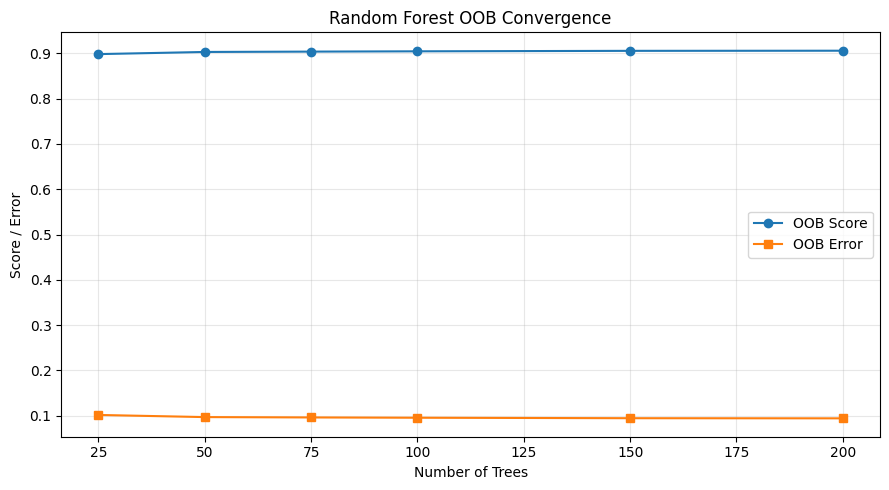


RUNNING GRID SEARCH
Parameters: {'model__n_estimators': [100, 200], 'model__max_features': ['sqrt', 'log2'], 'model__max_depth': [8, 12]}
Using 3-fold cross-validation and F1 scoring.
This may take several minutes.
Fitting 3 folds for each of 8 candidates, totalling 24 fits

GRID SEARCH SUMMARY
---------------------------------------------------------------------------
Best parameters: {'model__max_depth': 12, 'model__max_features': 'sqrt', 'model__n_estimators': 200}
Best CV F1: 0.3539

TUNED RANDOM FOREST RESULTS
---------------------------------------------------------------------------
OOB Score:       0.9005
OOB Error:       0.0995
Test Accuracy:   0.9014
Precision:       0.7374
Recall:          0.2443
Test F1 Score:   0.3670
ROC-AUC:         0.9243

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  No Deposit       0.91      0.99      0.95      9981
  Subscribed       0.74      0.24      0.37      1322

    accuracy                           0.90    

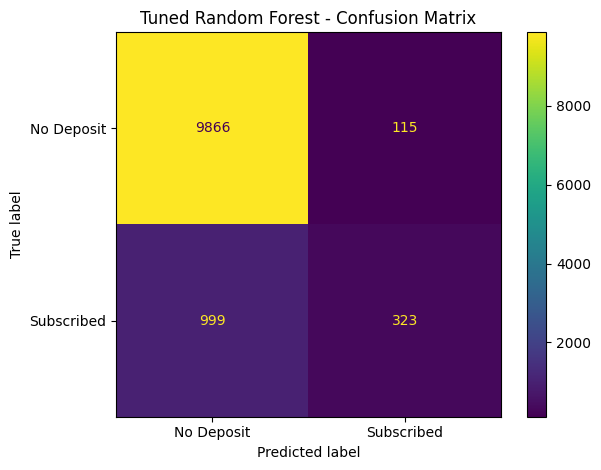


TOP MDI FEATURES
  Feature  MDI Importance
 duration         0.34330
 poutcome         0.13731
    month         0.11209
      age         0.06352
  balance         0.04592
    pdays         0.04579
      day         0.04323
  housing         0.04151
      job         0.04092
  contact         0.03279
 previous         0.02390
 campaign         0.01945
education         0.01941
  marital         0.01856
     loan         0.01045
  default         0.00185


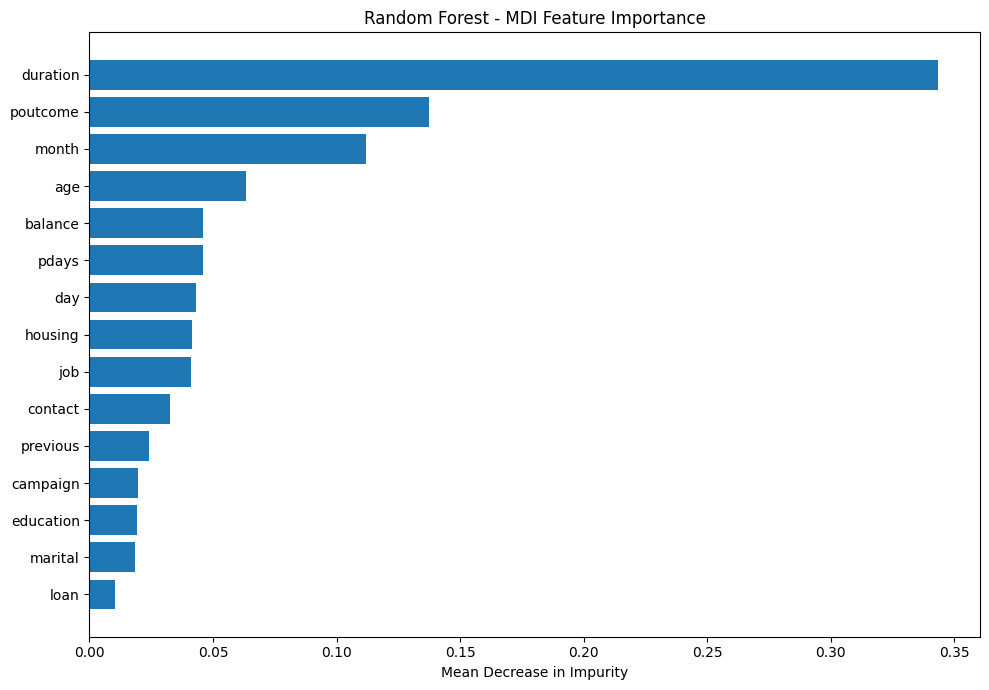


Calculating permutation importance...
This step can take a few minutes.

TOP PERMUTATION FEATURES
  Feature  Permutation Importance Mean  Permutation Importance Std
 poutcome                      0.17113                     0.00411
 duration                      0.13179                     0.00689
    pdays                      0.03941                     0.00201
 previous                      0.02339                     0.00159
  housing                      0.01620                     0.00200
  marital                      0.01417                     0.00427
    month                      0.01295                     0.00463
  contact                      0.01146                     0.00512
     loan                      0.00603                     0.00297
      age                      0.00539                     0.00325
 campaign                      0.00457                     0.00201
education                      0.00164                     0.00427
      job                     

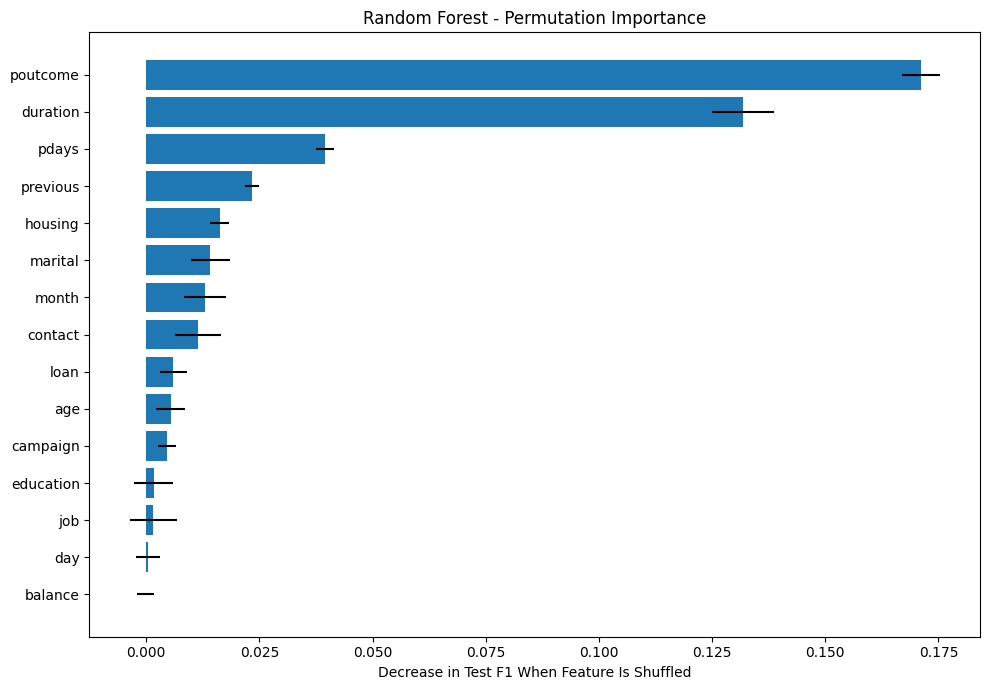


MDI VS PERMUTATION IMPORTANCE
  Feature  MDI Importance  Permutation Importance Mean  Permutation Importance Std
 poutcome         0.13731                      0.17113                     0.00411
 duration         0.34330                      0.13179                     0.00689
    pdays         0.04579                      0.03941                     0.00201
 previous         0.02390                      0.02339                     0.00159
  housing         0.04151                      0.01620                     0.00200
  marital         0.01856                      0.01417                     0.00427
    month         0.11209                      0.01295                     0.00463
  contact         0.03279                      0.01146                     0.00512
     loan         0.01045                      0.00603                     0.00297
      age         0.06352                      0.00539                     0.00325
 campaign         0.01945                      0.00457  

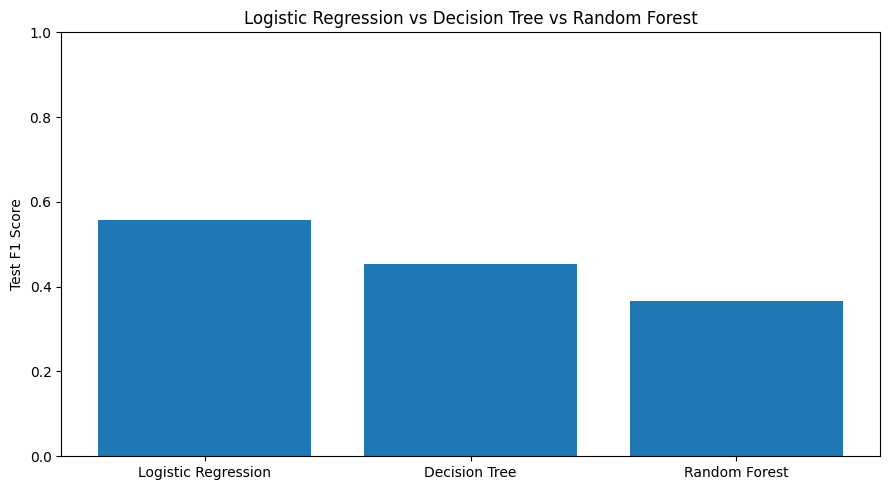


EXERCISE 4 - ACCEPTANCE CHECK
OOB Score: 0.9005 | Required: >= 0.88
Test F1:    0.3670 | Required: >= 0.65
OOB requirement: PASSED
F1 requirement: NOT MET

Top 3 MDI predictors:
['duration', 'poutcome', 'month']

Top 3 permutation predictors:
['poutcome', 'duration', 'pdays']

Expected predictors: ['age', 'duration', 'pdays']
Expected predictors appearing in top 3 MDI: ['duration']
Expected predictors appearing in top 3 permutation importance: ['duration', 'pdays']

SAVED OUTPUTS
---------------------------------------------------------------------------
Output folder: /content/exercise4_outputs
Plots folder: /content/exercise4_outputs/plots
CSV folder: /content/exercise4_outputs/csv

Exercise 4 code finished.


In [1]:
# ================================================================
# EXERCISE 4: RANDOM FOREST - COMPLETE LAB IMPLEMENTATION
# Requirements: OOB, GridSearchCV, MDI, Permutation Importance,
#               Model Benchmarking, Predictions, Diagnostic Outputs
# ================================================================

import io
import zipfile
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

# ================================================================
# 1. OUTPUT FOLDERS
# ================================================================

OUT = Path("exercise4_outputs")
PLOTS = OUT / "plots"
CSVS = OUT / "csv"

PLOTS.mkdir(parents=True, exist_ok=True)
CSVS.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("EXERCISE 4: RANDOM FOREST")
print("=" * 75)


# ================================================================
# 2. LOAD BANK MARKETING DATASET
# ================================================================

def parse_bank_csv(data):
    for sep in [";", ","]:
        try:
            frame = pd.read_csv(io.BytesIO(data), sep=sep)
            frame.columns = [
                str(c).strip().strip('"') for c in frame.columns
            ]
            if "y" in frame.columns and len(frame.columns) > 5:
                return frame
        except Exception:
            pass
    return None


def parse_bank_zip(data):
    try:
        with zipfile.ZipFile(io.BytesIO(data)) as z:
            files = z.namelist()

            preferred = [
                n for n in files
                if Path(n).name.lower() in
                ("bank-full.csv", "bank.csv")
            ]

            for name in preferred:
                frame = parse_bank_csv(z.read(name))
                if frame is not None:
                    return frame

            for name in files:
                if name.lower().endswith(".zip"):
                    frame = parse_bank_zip(z.read(name))
                    if frame is not None:
                        return frame

            for name in files:
                if name.lower().endswith(".csv"):
                    frame = parse_bank_csv(z.read(name))
                    if frame is not None:
                        return frame
    except Exception:
        pass

    return None


def load_dataset():
    for filename in [
        "bank-full.csv",
        "bank.csv",
        "bank_marketing.csv"
    ]:
        path = Path(filename)
        if path.exists():
            frame = pd.read_csv(path, sep=None, engine="python")
            frame.columns = [
                str(c).strip().strip('"') for c in frame.columns
            ]
            if "y" in frame.columns:
                print("Loaded local file:", path.resolve())
                return frame

    urls = [
        "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",
        "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank.zip"
    ]

    for url in urls:
        try:
            print("Trying download:", url)
            req = urllib.request.Request(
                url,
                headers={"User-Agent": "Mozilla/5.0"}
            )
            with urllib.request.urlopen(req, timeout=30) as response:
                data = response.read()

            frame = parse_bank_zip(data)
            if frame is not None:
                print("Dataset downloaded successfully.")
                return frame
        except Exception as exc:
            print("Download attempt failed:", str(exc)[:150])

    raise FileNotFoundError(
        "Dataset unavailable. Download bank-full.csv from "
        "https://archive.ics.uci.edu/dataset/222/bank+marketing "
        "and place it in the same folder as this notebook."
    )


df = load_dataset()
df.columns = [str(c).strip().strip('"') for c in df.columns]

if "y" not in df.columns:
    raise ValueError("The dataset must contain the target column 'y'.")

df["y"] = df["y"].astype(str).str.strip().str.lower()
df = df[df["y"].isin(["yes", "no"])].copy()
df["y"] = df["y"].map({"no": 0, "yes": 1}).astype(int)
df = df.drop_duplicates().reset_index(drop=True)

print("\nDATASET SUMMARY")
print("-" * 75)
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Target counts:")
print(df["y"].value_counts())
print("\nTarget proportions:")
print(df["y"].value_counts(normalize=True).round(4))


# ================================================================
# 3. FEATURES, TARGET, AND STRATIFIED SPLIT
# ================================================================

X = df.drop(columns=["y"]).copy()
y = df["y"].copy()

for col in X.columns:
    numeric_version = pd.to_numeric(X[col], errors="coerce")
    if numeric_version.notna().mean() > 0.90:
        X[col] = numeric_version

numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [
    col for col in X.columns if col not in numeric_cols
]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nDATA SPLIT")
print("-" * 75)
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


# ================================================================
# 4. PREPROCESSING PIPELINE
# ================================================================

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_transformer, numeric_cols),
            ("categorical", categorical_transformer, categorical_cols)
        ],
        remainder="drop"
    )


# ================================================================
# 5. BASELINE RANDOM FOREST WITH OOB SCORE
# ================================================================

baseline_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", RandomForestClassifier(
        n_estimators=100,
        oob_score=True,
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    ))
])

print("\nTraining baseline Random Forest...")
baseline_pipeline.fit(X_train, y_train)

baseline_rf = baseline_pipeline.named_steps["model"]
baseline_pred = baseline_pipeline.predict(X_test)

baseline_oob = baseline_rf.oob_score_
baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_f1 = f1_score(y_test, baseline_pred, zero_division=0)

print("\nBASELINE RESULTS")
print("-" * 75)
print(f"OOB Score:       {baseline_oob:.4f}")
print(f"Test Accuracy:   {baseline_accuracy:.4f}")
print(f"Test F1 Score:   {baseline_f1:.4f}")
print(f"Precision:       {precision_score(y_test, baseline_pred, zero_division=0):.4f}")
print(f"Recall:          {recall_score(y_test, baseline_pred, zero_division=0):.4f}")
print(f"OOB Error:       {1 - baseline_oob:.4f}")


# ================================================================
# 6. OOB SCORE CONVERGENCE
# ================================================================

tree_counts = [25, 50, 75, 100, 150, 200]
oob_records = []

for n_trees in tree_counts:
    print(f"Measuring OOB score with {n_trees} trees...")

    pipeline = Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("model", RandomForestClassifier(
            n_estimators=n_trees,
            oob_score=True,
            bootstrap=True,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        ))
    ])

    pipeline.fit(X_train, y_train)
    model = pipeline.named_steps["model"]

    oob_records.append({
        "Number of Trees": n_trees,
        "OOB Score": model.oob_score_,
        "OOB Error": 1 - model.oob_score_
    })

oob_df = pd.DataFrame(oob_records)
oob_df.to_csv(CSVS / "oob_convergence.csv", index=False)

print("\nOOB CONVERGENCE TABLE")
print(oob_df.round(4).to_string(index=False))

plt.figure(figsize=(9, 5))
plt.plot(
    oob_df["Number of Trees"],
    oob_df["OOB Score"],
    marker="o",
    label="OOB Score"
)
plt.plot(
    oob_df["Number of Trees"],
    oob_df["OOB Error"],
    marker="s",
    label="OOB Error"
)
plt.xlabel("Number of Trees")
plt.ylabel("Score / Error")
plt.title("Random Forest OOB Convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS / "oob_convergence.png", dpi=150)
plt.show()


# ================================================================
# 7. REQUIRED GRID SEARCH
# ================================================================

tuning_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", RandomForestClassifier(
        oob_score=True,
        bootstrap=True,
        random_state=42,
        n_jobs=1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_features": ["sqrt", "log2"],
    "model__max_depth": [8, 12]
}

print("\nRUNNING GRID SEARCH")
print("Parameters:", param_grid)
print("Using 3-fold cross-validation and F1 scoring.")
print("This may take several minutes.")

grid = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    verbose=1
)

grid.fit(X_train, y_train)

best_pipeline = grid.best_estimator_
best_rf = best_pipeline.named_steps["model"]

print("\nGRID SEARCH SUMMARY")
print("-" * 75)
print("Best parameters:", grid.best_params_)
print(f"Best CV F1: {grid.best_score_:.4f}")

grid_results = pd.DataFrame(grid.cv_results_)
grid_results.to_csv(CSVS / "grid_search_results.csv", index=False)


# ================================================================
# 8. EVALUATE TUNED RANDOM FOREST
# ================================================================

rf_pred = best_pipeline.predict(X_test)
rf_prob = best_pipeline.predict_proba(X_test)[:, 1]

rf_oob = best_rf.oob_score_
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, zero_division=0)
rf_auc = roc_auc_score(y_test, rf_prob)

print("\nTUNED RANDOM FOREST RESULTS")
print("-" * 75)
print(f"OOB Score:       {rf_oob:.4f}")
print(f"OOB Error:       {1 - rf_oob:.4f}")
print(f"Test Accuracy:   {rf_accuracy:.4f}")
print(f"Precision:       {rf_precision:.4f}")
print(f"Recall:          {rf_recall:.4f}")
print(f"Test F1 Score:   {rf_f1:.4f}")
print(f"ROC-AUC:         {rf_auc:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    rf_pred,
    labels=[0, 1],
    target_names=["No Deposit", "Subscribed"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    labels=[0, 1],
    display_labels=["No Deposit", "Subscribed"]
)
plt.title("Tuned Random Forest - Confusion Matrix")
plt.tight_layout()
plt.savefig(PLOTS / "random_forest_confusion_matrix.png", dpi=150)
plt.show()


# ================================================================
# 9. MEAN DECREASE IN IMPURITY (MDI) IMPORTANCE
# ================================================================

preprocessor_fitted = best_pipeline.named_steps["preprocessor"]
encoded_names = preprocessor_fitted.get_feature_names_out()

mdi_df = pd.DataFrame({
    "Encoded Feature": encoded_names,
    "MDI Importance": best_rf.feature_importances_
}).sort_values("MDI Importance", ascending=False)

mdi_df.to_csv(CSVS / "mdi_feature_importance_encoded.csv", index=False)

def get_original_feature(encoded_name):
    name = str(encoded_name)

    if name.startswith("numeric__"):
        return name[len("numeric__"):]

    if name.startswith("categorical__"):
        name = name[len("categorical__"):]

    # Match original categorical column prefixes.
    for original in sorted(categorical_cols, key=len, reverse=True):
        if name == original or name.startswith(original + "_"):
            return original

    return name


mdi_df["Feature"] = mdi_df["Encoded Feature"].apply(get_original_feature)

mdi_original = (
    mdi_df.groupby("Feature", as_index=False)["MDI Importance"]
    .sum()
    .sort_values("MDI Importance", ascending=False)
)

mdi_original.to_csv(CSVS / "mdi_feature_importance.csv", index=False)

print("\nTOP MDI FEATURES")
print(mdi_original.head(20).round(5).to_string(index=False))

top_mdi = mdi_original.head(15).sort_values("MDI Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_mdi["Feature"], top_mdi["MDI Importance"])
plt.xlabel("Mean Decrease in Impurity")
plt.title("Random Forest - MDI Feature Importance")
plt.tight_layout()
plt.savefig(PLOTS / "mdi_feature_importance.png", dpi=150)
plt.show()


# ================================================================
# 10. PERMUTATION IMPORTANCE ON TEST DATA
# ================================================================

print("\nCalculating permutation importance...")
print("This step can take a few minutes.")

perm = permutation_importance(
    best_pipeline,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Permutation Importance Mean": perm.importances_mean,
    "Permutation Importance Std": perm.importances_std
}).sort_values("Permutation Importance Mean", ascending=False)

perm_df.to_csv(CSVS / "permutation_feature_importance.csv", index=False)

print("\nTOP PERMUTATION FEATURES")
print(perm_df.head(20).round(5).to_string(index=False))

top_perm = perm_df.head(15).sort_values(
    "Permutation Importance Mean"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_perm["Feature"],
    top_perm["Permutation Importance Mean"],
    xerr=top_perm["Permutation Importance Std"]
)
plt.xlabel("Decrease in Test F1 When Feature Is Shuffled")
plt.title("Random Forest - Permutation Importance")
plt.tight_layout()
plt.savefig(PLOTS / "permutation_feature_importance.png", dpi=150)
plt.show()


# ================================================================
# 11. COMPARE MDI AND PERMUTATION IMPORTANCE
# ================================================================

importance_comparison = pd.merge(
    mdi_original,
    perm_df,
    on="Feature",
    how="outer"
).fillna(0)

importance_comparison.to_csv(
    CSVS / "mdi_vs_permutation_importance.csv",
    index=False
)

print("\nMDI VS PERMUTATION IMPORTANCE")
print(importance_comparison.sort_values(
    "Permutation Importance Mean", ascending=False
).head(20).round(5).to_string(index=False))


# ================================================================
# 12. BENCHMARK LOGISTIC REGRESSION, DECISION TREE, RANDOM FOREST
# ================================================================

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            solver="lbfgs",
            random_state=42
        ))
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("model", DecisionTreeClassifier(
            criterion="gini",
            max_depth=5,
            min_samples_split=20,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "Random Forest": best_pipeline
}

benchmark_records = []

for name, model in models.items():
    print("Benchmarking:", name)

    # Fit the model using training data only.
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    benchmark_records.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "Test F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

benchmark_df = pd.DataFrame(benchmark_records).sort_values(
    "Test F1", ascending=False
)

benchmark_df.to_csv(CSVS / "model_benchmark_comparison.csv", index=False)

print("\nMODEL BENCHMARK TABLE")
print(benchmark_df.round(4).to_string(index=False))

plt.figure(figsize=(9, 5))
plt.bar(benchmark_df["Model"], benchmark_df["Test F1"])
plt.ylabel("Test F1 Score")
plt.title("Logistic Regression vs Decision Tree vs Random Forest")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(PLOTS / "model_f1_comparison.png", dpi=150)
plt.show()


# ================================================================
# 13. EXPORT TEST PREDICTIONS
# ================================================================

prediction_df = X_test.copy()
prediction_df["Actual"] = y_test
prediction_df["Predicted"] = rf_pred
prediction_df["Subscription Probability"] = rf_prob

prediction_df.to_csv(
    CSVS / "random_forest_test_predictions.csv",
    index=False
)


# ================================================================
# 14. CHECK LAB ACCEPTANCE REQUIREMENTS
# ================================================================

top_mdi_names = set(mdi_original.head(3)["Feature"])
top_perm_names = set(perm_df.head(3)["Feature"])

expected_features = {"duration", "pdays", "age"}

print("\n" + "=" * 75)
print("EXERCISE 4 - ACCEPTANCE CHECK")
print("=" * 75)

print(f"OOB Score: {rf_oob:.4f} | Required: >= 0.88")
print(f"Test F1:    {rf_f1:.4f} | Required: >= 0.65")

print(
    "OOB requirement:",
    "PASSED" if rf_oob >= 0.88 else "NOT MET"
)
print(
    "F1 requirement:",
    "PASSED" if rf_f1 >= 0.65 else "NOT MET"
)

print("\nTop 3 MDI predictors:")
print(mdi_original.head(3)["Feature"].tolist())

print("\nTop 3 permutation predictors:")
print(perm_df.head(3)["Feature"].tolist())

print("\nExpected predictors:", sorted(expected_features))
print("Expected predictors appearing in top 3 MDI:",
      sorted(expected_features.intersection(top_mdi_names)))
print("Expected predictors appearing in top 3 permutation importance:",
      sorted(expected_features.intersection(top_perm_names)))

# Save the key metrics.
summary = pd.DataFrame([{
    "Baseline OOB Score": baseline_oob,
    "Baseline Test Accuracy": baseline_accuracy,
    "Baseline Test F1": baseline_f1,
    "Tuned OOB Score": rf_oob,
    "Tuned Test Accuracy": rf_accuracy,
    "Tuned Test Precision": rf_precision,
    "Tuned Test Recall": rf_recall,
    "Tuned Test F1": rf_f1,
    "Tuned ROC-AUC": rf_auc,
    "Best CV F1": grid.best_score_,
    "OOB Target Met": rf_oob >= 0.88,
    "F1 Target Met": rf_f1 >= 0.65
}])

summary.to_csv(CSVS / "exercise4_metrics_summary.csv", index=False)

print("\nSAVED OUTPUTS")
print("-" * 75)
print("Output folder:", OUT.resolve())
print("Plots folder:", PLOTS.resolve())
print("CSV folder:", CSVS.resolve())
print("\nExercise 4 code finished.")

EXERCISE 5: K-MEANS CLUSTERING
Wholesale Spending Personas

Trying dataset source: https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip
Dataset loaded successfully.

DATASET INFORMATION
---------------------------------------------------------------------------
Rows: 440
Columns: 8

First five records:
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185

MISSING VALUES
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

DESCRIPTIVE STATISTICS
           Fresh    

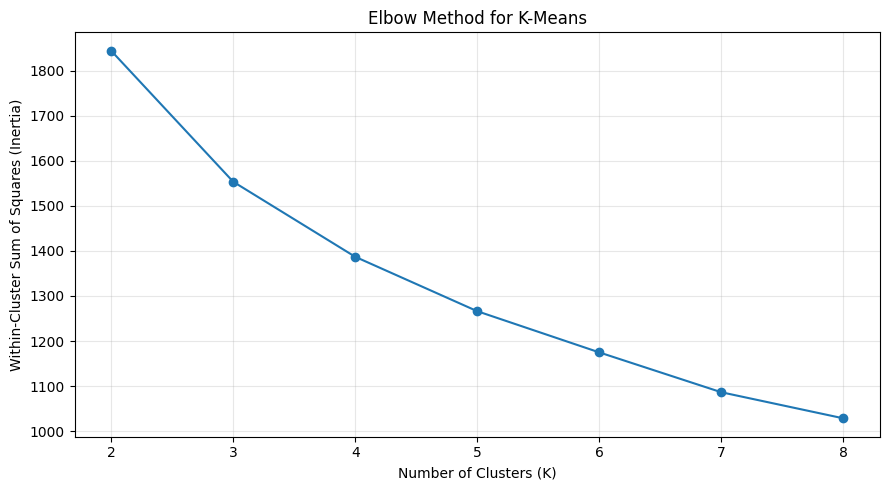


SILHOUETTE ANALYSIS
---------------------------------------------------------------------------
 K  Silhouette Score
 2            0.2903
 3            0.2594
 4            0.1885
 5            0.1916
 6            0.2009
 7            0.1958
 8            0.1852

K with the highest silhouette score: 2


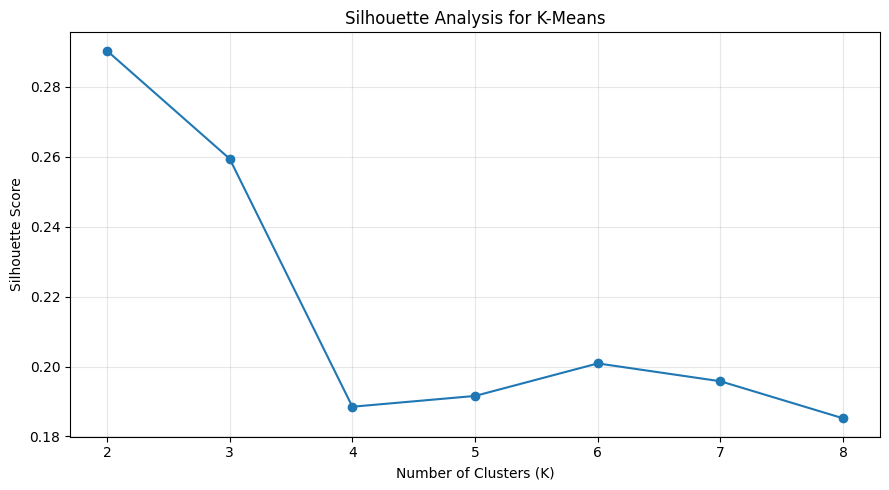


FINAL K-MEANS MODEL
---------------------------------------------------------------------------
Selected number of clusters: 4
Silhouette score for K=4: 0.1885

CUSTOMER COUNT PER CLUSTER
Cluster
0     61
1    129
2    132
3    118
Name: count, dtype: int64

CLUSTER SPENDING PROFILE - ORIGINAL VALUES
---------------------------------------------------------------------------
 Cluster    Fresh     Milk  Grocery  Frozen  Detergents_Paper  Delicassen  Customer_Count  Customer_Percentage
       0  2809.05  7061.84 12349.33  565.59           5342.62      635.84              61                13.86
       1 19374.38  4068.11  4444.94 6184.33            723.33     2322.71             129                29.32
       2  9632.66  1569.58  2071.87 2175.23            345.01      584.81             132                30.00
       3 11338.75 11759.44 16087.87 1968.13           6805.99     2163.83             118                26.82


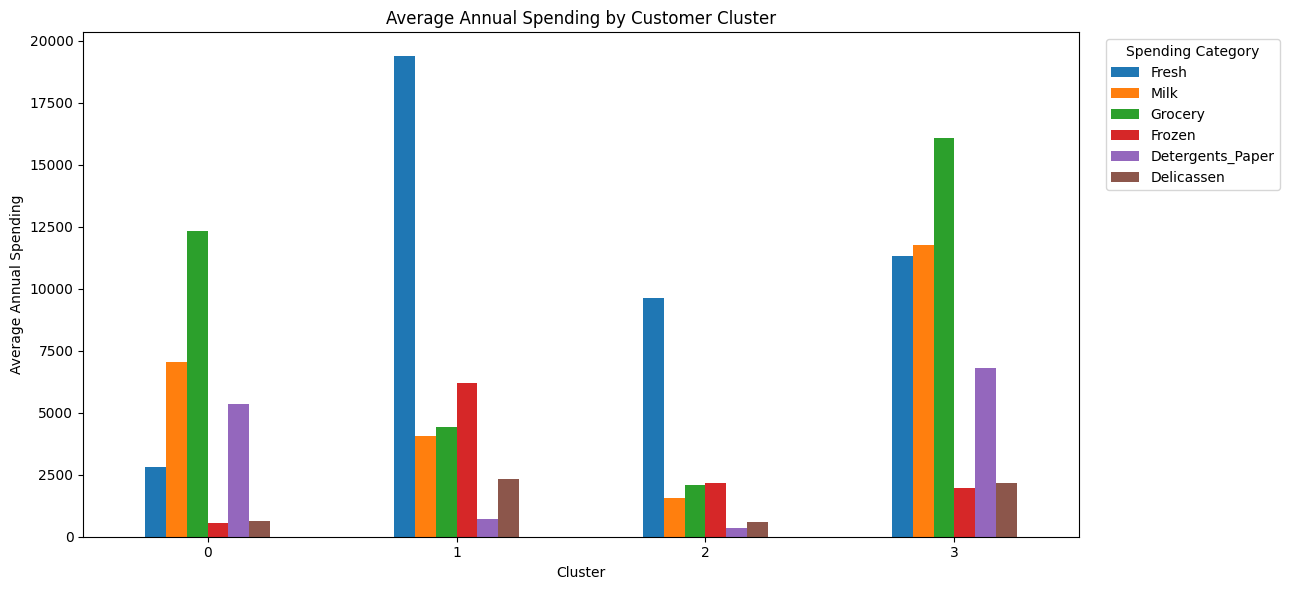

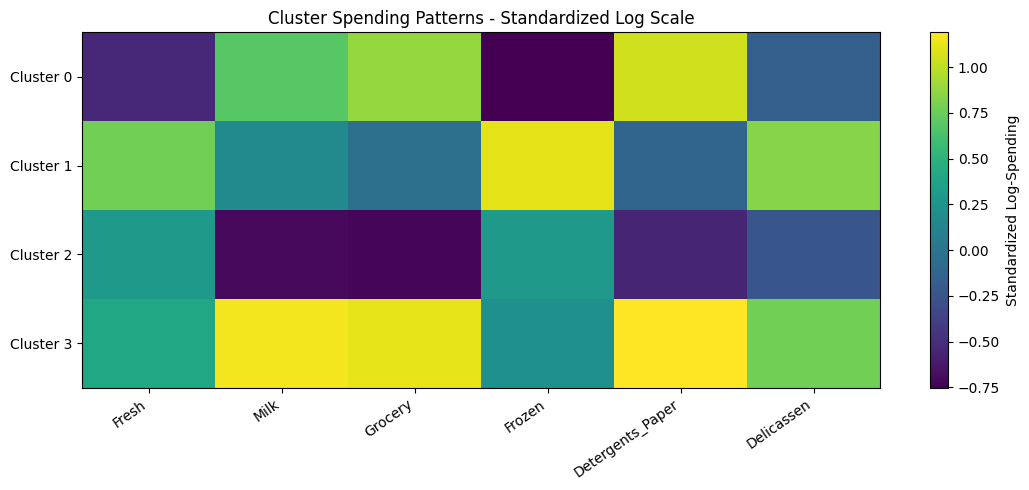

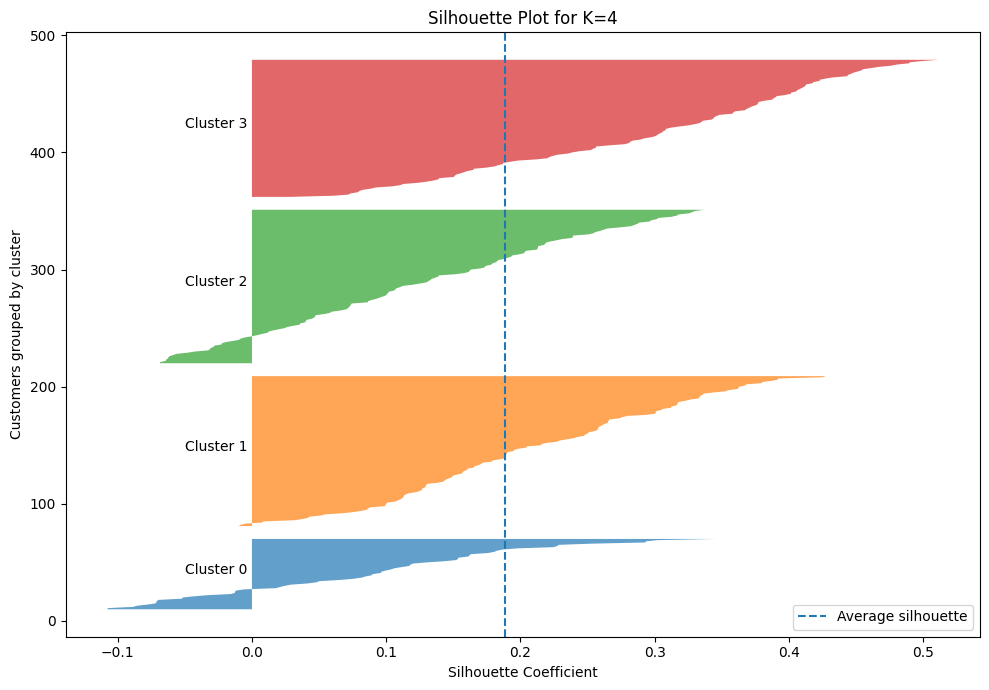


BUSINESS PERSONA SUMMARY
---------------------------------------------------------------------------
 Cluster  Customer_Count  Customer_Percentage                Suggested Persona
       0              61                13.86 Supermarkets / Grocery Retailers
       1             129                29.32                    Fresh Markets
       2             132                30.00                    Fresh Markets
       3             118                26.82           Boutique Delicatessens

ACTIONABLE BUSINESS RECOMMENDATIONS
---------------------------------------------------------------------------

Cluster 0: Supermarkets / Grocery Retailers
Customers: 61
Inventory: Prioritize dependable grocery and detergent/paper supply, volume discounts, and scheduled bulk replenishment.
Credit strategy: Consider credit limits based on verified purchase history and stable high-volume ordering.

Cluster 1: Fresh Markets
Customers: 129
Inventory: Prioritize fresh inventory availability, frequent 

In [2]:
# ================================================================
# EXERCISE 5: K-MEANS CLUSTERING - WHOLESALE SPENDING PERSONAS
# Complete Machine Learning Engineering Lab
# ================================================================

import io
import zipfile
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples

warnings.filterwarnings("ignore")

# ================================================================
# 1. CREATE OUTPUT FOLDERS
# ================================================================

OUT = Path("exercise5_outputs")
PLOTS = OUT / "plots"
CSVS = OUT / "csv"

PLOTS.mkdir(parents=True, exist_ok=True)
CSVS.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("EXERCISE 5: K-MEANS CLUSTERING")
print("Wholesale Spending Personas")
print("=" * 75)


# ================================================================
# 2. LOAD WHOLESALE CUSTOMERS DATASET
# ================================================================

EXPECTED_COLUMNS = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]


def read_wholesale_csv(data):
    """Read a CSV from bytes and identify the six spending columns."""
    try:
        frame = pd.read_csv(io.BytesIO(data))
        frame.columns = [
            str(c).strip().replace(" ", "_")
            for c in frame.columns
        ]

        # Handle common spelling/capitalization variations.
        lookup = {c.lower(): c for c in frame.columns}

        required_lower = [c.lower() for c in EXPECTED_COLUMNS]

        if all(c in lookup for c in required_lower):
            rename_map = {
                lookup[c.lower()]: c for c in EXPECTED_COLUMNS
            }
            frame = frame.rename(columns=rename_map)
            return frame

    except Exception:
        pass

    return None


def read_wholesale_zip(data):
    """Find a suitable CSV in a downloaded ZIP archive."""
    try:
        with zipfile.ZipFile(io.BytesIO(data)) as archive:
            for name in archive.namelist():
                if name.lower().endswith(".csv"):
                    frame = read_wholesale_csv(archive.read(name))
                    if frame is not None:
                        return frame
    except Exception:
        pass

    return None


def load_wholesale_dataset():
    # Try files already downloaded into the notebook folder.
    local_files = [
        "Wholesale customers data.csv",
        "wholesale_customers_data.csv",
        "wholesale.csv",
        "wholesale_customers.csv"
    ]

    for filename in local_files:
        path = Path(filename)

        if path.exists():
            frame = pd.read_csv(path)
            frame.columns = [
                str(c).strip().replace(" ", "_")
                for c in frame.columns
            ]

            lookup = {c.lower(): c for c in frame.columns}

            if all(c.lower() in lookup for c in EXPECTED_COLUMNS):
                frame = frame.rename(columns={
                    lookup[c.lower()]: c for c in EXPECTED_COLUMNS
                })
                print("Loaded local dataset:", path.resolve())
                return frame

    # Try the official UCI archive.
    urls = [
        "https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip",
        "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
    ]

    for url in urls:
        try:
            print("\nTrying dataset source:", url)

            request = urllib.request.Request(
                url,
                headers={"User-Agent": "Mozilla/5.0"}
            )

            with urllib.request.urlopen(request, timeout=30) as response:
                data = response.read()

            if zipfile.is_zipfile(io.BytesIO(data)):
                frame = read_wholesale_zip(data)
            else:
                frame = read_wholesale_csv(data)

            if frame is not None:
                print("Dataset loaded successfully.")
                return frame

        except Exception as error:
            print("Source unavailable:", str(error)[:180])

    raise FileNotFoundError(
        "\nUnable to download the Wholesale Customers dataset.\n"
        "Download it from:\n"
        "https://archive.ics.uci.edu/dataset/292/wholesale+customers\n"
        "Save the CSV as 'Wholesale customers data.csv' in the same "
        "folder as this notebook, then run the cell again."
    )


df = load_wholesale_dataset()

print("\nDATASET INFORMATION")
print("-" * 75)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nFirst five records:")
print(df.head())

# ================================================================
# 3. DATA QUALITY CHECKS
# ================================================================

spending_columns = EXPECTED_COLUMNS.copy()

missing_columns = [
    col for col in spending_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        "Missing required spending columns: " + str(missing_columns)
    )

# Use only the six annual spending categories for clustering.
# Channel and Region, if present, are not used as clustering features.
X = df[spending_columns].copy()

for col in spending_columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

print("\nMISSING VALUES")
print(X.isna().sum())

# Impute missing values using the column median if necessary.
X = X.fillna(X.median())

# Spending values should not be negative.
if (X < 0).any().any():
    raise ValueError("Negative spending values were found in the dataset.")

print("\nDESCRIPTIVE STATISTICS")
print(X.describe().round(2))

print("\nSKEWNESS BEFORE TRANSFORMATION")
print(X.skew().round(3))

# Save basic statistics.
X.describe().T.to_csv(CSVS / "original_spending_statistics.csv")


# ================================================================
# 4. LOG1P TRANSFORMATION
# ================================================================
# The lab guide requires np.log1p() to reduce right skew.

X_log = np.log1p(X)

print("\nSKEWNESS AFTER LOG1P TRANSFORMATION")
print(X_log.skew().round(3))

skewness_comparison = pd.DataFrame({
    "Feature": spending_columns,
    "Skewness Before": X.skew().values,
    "Skewness After Log1p": X_log.skew().values
})

skewness_comparison.to_csv(
    CSVS / "skewness_comparison.csv",
    index=False
)

print("\nSKEWNESS COMPARISON")
print(skewness_comparison.round(3).to_string(index=False))


# ================================================================
# 5. STANDARDIZATION
# ================================================================
# Fit the scaler on the transformed data.
# All six features are placed on a comparable scale.

scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X_log)

X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=spending_columns,
    index=X.index
)

print("\nSTANDARDIZED FEATURE CHECK")
print(X_scaled.describe().round(3))

X_scaled.to_csv(CSVS / "log1p_standardized_features.csv", index=False)


# ================================================================
# 6. ELBOW METHOD: K FROM 2 TO 8
# ================================================================

k_values = list(range(2, 9))
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertias.append(model.inertia_)

elbow_df = pd.DataFrame({
    "K": k_values,
    "Inertia": inertias
})

elbow_df.to_csv(CSVS / "elbow_results.csv", index=False)

print("\nELBOW METHOD RESULTS")
print("-" * 75)
print(elbow_df.round(3).to_string(index=False))

plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias, marker="o")
plt.xticks(k_values)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.title("Elbow Method for K-Means")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS / "elbow_method.png", dpi=150)
plt.show()


# ================================================================
# 7. SILHOUETTE ANALYSIS: K FROM 2 TO 8
# ================================================================

silhouette_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(2000, len(X_scaled)),
        random_state=42
    )

    silhouette_values.append(score)

silhouette_df = pd.DataFrame({
    "K": k_values,
    "Silhouette Score": silhouette_values
})

silhouette_df.to_csv(
    CSVS / "silhouette_results.csv",
    index=False
)

print("\nSILHOUETTE ANALYSIS")
print("-" * 75)
print(silhouette_df.round(4).to_string(index=False))

best_silhouette_k = int(
    silhouette_df.loc[
        silhouette_df["Silhouette Score"].idxmax(), "K"
    ]
)

print("\nK with the highest silhouette score:", best_silhouette_k)

plt.figure(figsize=(9, 5))
plt.plot(
    k_values,
    silhouette_values,
    marker="o"
)
plt.xticks(k_values)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis for K-Means")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS / "silhouette_analysis.png", dpi=150)
plt.show()


# ================================================================
# 8. SELECT K=4 AS REQUIRED BY THE LAB GUIDE
# ================================================================
# The guide specifies four customer personas.
# We use K=4 for the final profile, regardless of which K scores best.

FINAL_K = 4

kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

df_results = df.copy()
df_results["Cluster"] = cluster_labels

print("\nFINAL K-MEANS MODEL")
print("-" * 75)
print("Selected number of clusters:", FINAL_K)
print(
    "Silhouette score for K=4:",
    f"{silhouette_score(X_scaled, cluster_labels):.4f}"
)

print("\nCUSTOMER COUNT PER CLUSTER")
print(df_results["Cluster"].value_counts().sort_index())


# ================================================================
# 9. PROFILE CLUSTERS USING ORIGINAL EURO SPENDING
# ================================================================
# Use original, unscaled spending for business interpretation.

cluster_profile = df_results.groupby("Cluster")[
    spending_columns
].mean()

cluster_profile["Customer_Count"] = (
    df_results.groupby("Cluster").size()
)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"] / len(df_results) * 100
)

cluster_profile = cluster_profile.reset_index()

cluster_profile.to_csv(
    CSVS / "cluster_spending_profile.csv",
    index=False
)

print("\nCLUSTER SPENDING PROFILE - ORIGINAL VALUES")
print("-" * 75)
print(cluster_profile.round(2).to_string(index=False))


# ================================================================
# 10. VISUALIZE CLUSTER PROFILES
# ================================================================

profile_plot = cluster_profile.set_index("Cluster")[spending_columns]

ax = profile_plot.plot(
    kind="bar",
    figsize=(13, 6)
)

ax.set_title("Average Annual Spending by Customer Cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Average Annual Spending")
plt.xticks(rotation=0)
plt.legend(title="Spending Category", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig(
    PLOTS / "cluster_spending_profiles.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


# ================================================================
# 11. HEATMAP-STYLE STANDARDIZED CLUSTER PROFILES
# ================================================================
# The heatmap shows which categories are relatively high or low
# compared with the overall customer population.

cluster_means_scaled = pd.DataFrame(
    scaler.transform(np.log1p(cluster_profile[spending_columns])),
    columns=spending_columns,
    index=cluster_profile["Cluster"]
)

# The scaler above was fitted to individual customers, so the
# transformed cluster means provide a relative spending view.

plt.figure(figsize=(11, 5))
plt.imshow(
    cluster_means_scaled.values,
    aspect="auto"
)
plt.colorbar(label="Standardized Log-Spending")
plt.xticks(
    range(len(spending_columns)),
    spending_columns,
    rotation=35,
    ha="right"
)
plt.yticks(
    range(len(cluster_means_scaled.index)),
    [f"Cluster {c}" for c in cluster_means_scaled.index]
)
plt.title("Cluster Spending Patterns - Standardized Log Scale")
plt.tight_layout()
plt.savefig(
    PLOTS / "cluster_profile_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


# ================================================================
# 12. SILHOUETTE PLOT FOR K=4
# ================================================================

sample_silhouette_values = silhouette_samples(
    X_scaled,
    cluster_labels
)

plt.figure(figsize=(10, 7))

y_lower = 10

for cluster_id in range(FINAL_K):
    values = sample_silhouette_values[
        cluster_labels == cluster_id
    ]

    values.sort()
    cluster_size = len(values)
    y_upper = y_lower + cluster_size

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        values,
        alpha=0.7
    )

    plt.text(
        -0.05,
        y_lower + cluster_size / 2,
        f"Cluster {cluster_id}"
    )

    y_lower = y_upper + 10

plt.axvline(
    silhouette_score(X_scaled, cluster_labels),
    linestyle="--",
    label="Average silhouette"
)

plt.xlabel("Silhouette Coefficient")
plt.ylabel("Customers grouped by cluster")
plt.title("Silhouette Plot for K=4")
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS / "silhouette_plot_k4.png", dpi=150)
plt.show()


# ================================================================
# 13. AUTOMATIC BUSINESS PERSONA LABELS
# ================================================================
# These labels are heuristics based on relative category spending.
# They are not known ground-truth customer labels.

persona_names = {
    0: "Supermarkets / Grocery Retailers",
    1: "Horeca / Restaurants",
    2: "Fresh Markets",
    3: "Boutique Delicatessens"
}

def recommend_persona(row):
    """
    Create a transparent heuristic label from the cluster's
    average original spending. Labels are assigned by spending
    pattern and are not guaranteed to match real-world customer type.
    """
    fresh = row["Fresh"]
    milk = row["Milk"]
    grocery = row["Grocery"]
    frozen = row["Frozen"]
    detergents = row["Detergents_Paper"]
    delicassen = row["Delicassen"]

    if grocery + detergents >= fresh + frozen + milk:
        return "Supermarkets / Grocery Retailers"

    if fresh >= max(milk, grocery, frozen, detergents, delicassen):
        return "Fresh Markets"

    if frozen + milk >= fresh + grocery:
        return "Horeca / Restaurants"

    return "Boutique Delicatessens"


# Assign personas from the observed cluster spending profiles.
# Cluster IDs are arbitrary; the profile determines the description.
cluster_profile["Suggested Persona"] = cluster_profile.apply(
    recommend_persona,
    axis=1
)

# Save profile with persona suggestions.
cluster_profile.to_csv(
    CSVS / "cluster_profiles_with_personas.csv",
    index=False
)

persona_lookup = dict(zip(
    cluster_profile["Cluster"],
    cluster_profile["Suggested Persona"]
))

df_results["Suggested Persona"] = (
    df_results["Cluster"].map(persona_lookup)
)

print("\nBUSINESS PERSONA SUMMARY")
print("-" * 75)
print(
    cluster_profile[
        ["Cluster", "Customer_Count", "Customer_Percentage",
         "Suggested Persona"]
    ].round(2).to_string(index=False)
)


# ================================================================
# 14. BUSINESS RECOMMENDATIONS
# ================================================================

recommendations = {
    "Supermarkets / Grocery Retailers": (
        "Prioritize dependable grocery and detergent/paper supply, "
        "volume discounts, and scheduled bulk replenishment."
    ),
    "Horeca / Restaurants": (
        "Offer flexible deliveries, fresh and dairy product bundles, "
        "and seasonal order planning."
    ),
    "Fresh Markets": (
        "Prioritize fresh inventory availability, frequent deliveries, "
        "and short replenishment cycles."
    ),
    "Boutique Delicatessens": (
        "Offer smaller specialty assortments, premium product options, "
        "and flexible order quantities."
    )
}

cluster_profile["Inventory Recommendation"] = (
    cluster_profile["Suggested Persona"].map(recommendations)
)

cluster_profile["Credit Strategy"] = (
    cluster_profile["Suggested Persona"].map({
        "Supermarkets / Grocery Retailers":
            "Consider credit limits based on verified purchase history "
            "and stable high-volume ordering.",
        "Horeca / Restaurants":
            "Consider moderate flexible credit and review payment cycles "
            "alongside seasonal demand.",
        "Fresh Markets":
            "Consider shorter credit review cycles aligned with frequent "
            "replenishment and cash-flow patterns.",
        "Boutique Delicatessens":
            "Start with controlled limits and adjust using verified "
            "payment history and order consistency."
    })
)

cluster_profile.to_csv(
    CSVS / "business_recommendations.csv",
    index=False
)

print("\nACTIONABLE BUSINESS RECOMMENDATIONS")
print("-" * 75)

for _, row in cluster_profile.iterrows():
    print(f"\nCluster {int(row['Cluster'])}: {row['Suggested Persona']}")
    print("Customers:", int(row["Customer_Count"]))
    print("Inventory:", row["Inventory Recommendation"])
    print("Credit strategy:", row["Credit Strategy"])


# ================================================================
# 15. EXPORT CUSTOMER ASSIGNMENTS
# ================================================================

df_results.to_csv(
    CSVS / "wholesale_customer_cluster_assignments.csv",
    index=False
)

# Export centroids in original spending units.
# These are the average original spending values per cluster.
cluster_centroids = cluster_profile[
    ["Cluster"] + spending_columns
].copy()

cluster_centroids.to_csv(
    CSVS / "cluster_centroids_original_spending.csv",
    index=False
)


# ================================================================
# 16. ACCEPTANCE CRITERIA
# ================================================================

final_silhouette = silhouette_score(
    X_scaled,
    cluster_labels
)

print("\n" + "=" * 75)
print("EXERCISE 5 ACCEPTANCE CHECK")
print("=" * 75)

print("Selected K:", FINAL_K)
print(f"Silhouette score for K=4: {final_silhouette:.4f}")
print("Guide target silhouette score: >= 0.42")
print(
    "Silhouette target:",
    "PASSED" if final_silhouette >= 0.42 else "NOT MET"
)

print("\nSilhouette scores for K=2 through K=8:")
print(silhouette_df.round(4).to_string(index=False))

print("\nNOTE:")
print(
    "The elbow bend and silhouette maximum are empirical results. "
    "K=4 is used for final profiling because the lab guide specifies "
    "four business personas."
)

print("\nOUTPUT DIRECTORIES")
print("-" * 75)
print("Main output:", OUT.resolve())
print("Plots:", PLOTS.resolve())
print("CSV files:", CSVS.resolve())

print("\nEXERCISE 5 COMPLETED SUCCESSFULLY.")